# H2 benchmark: EfficientSU2, UCCSD and fUCCSD with ZNE and CDR

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

## Setup

In [2]:
import contextlib
import io
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from pyscf import mcscf
from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.operators import FermionicOp
from slowquant.qiskit_interface.circuit_wavefunction import WaveFunctionCircuit
from slowquant.qiskit_interface.interface import QuantumInterface

from src.utils import load_config
from src.chem import get_molecule, get_problem, get_ansatz
from src.backend import run_vqe, get_transpiled
from src.mitigation import ZNE, CDR, M0

load_config("configs/h2.yaml")

molecule, mf, cas = get_molecule()
problem = get_problem()
e_nuc = molecule.energy_nuc()
mapper = JordanWignerMapper()

E_hf = mf.e_tot
E_fci = mcscf.CASCI(mf, cas[1], cas[0]).run().e_tot
print(f"HF  : {E_hf:.6f} Ha")
print(f"FCI : {E_fci:.6f} Ha")


Setting number of Numba threads to 1

HF  : -1.116999 Ha
FCI : -1.137306 Ha


## Ansatze

Each ansatz comes with its own Hamiltonian:

- **EfficientSU2, UCCSD** use the Qiskit Nature Hamiltonian.
- **fUCCSD** uses the Hamiltonian from SlowQuant's wavefunction, so it matches SlowQuant's orbitals.

UCCSD and fUCCSD start from θ = 0 (the HF state). EfficientSU2 starts from small random values, because θ = 0 is not the HF state for it.

In [3]:
ANSATZE = ["EfficientSU2", "UCCSD", "fUCCSD", "pp-tUPS"]
results = {name: {} for name in ANSATZE}

## VQE (noiseless) and transpiling

In [4]:
for name in ANSATZE:
    ansatz, hamiltonian, x0 = get_ansatz(name)
    vqe_energy, theta_opt = run_vqe(ansatz, hamiltonian, x0)
    transpiled_ansatz, transpiled_hamiltonian = get_transpiled(ansatz, theta_opt, hamiltonian)

    results[name].update(
        ansatz=ansatz,
        hamiltonian=hamiltonian,
        theta_opt=theta_opt,
        transpiled_ansatz=transpiled_ansatz,
        transpiled_hamiltonian=transpiled_hamiltonian,
        E_exact=vqe_energy + e_nuc,
    )
    print(f"{name:13s} params = {ansatz.num_parameters:3d}   "
          f"E_VQE = {vqe_energy + e_nuc:.6f} Ha   "
          f"error vs FCI = {abs(vqe_energy + e_nuc - E_fci):.2e} Ha   "
          f"transpiled depth = {transpiled_ansatz.depth()}")

    print(results[name]["theta_opt"])

EfficientSU2  params =  16   E_VQE = -1.137306 Ha   error vs FCI = 2.65e-07 Ha   transpiled depth = 16
[-2.24115764e-01 -7.86598106e-06  3.14117293e+00  2.73972284e-04
 -3.35120234e+00  2.95220736e+00  8.60836090e-01  2.89858786e+00
 -3.14124999e+00  2.97557661e-04 -2.05563587e-04  3.14181624e+00
  1.63365753e+00  1.29825015e+00  2.63233136e-01 -2.33257463e+00]
UCCSD         params =   3   E_VQE = -1.137306 Ha   error vs FCI = 5.73e-11 Ha   transpiled depth = 135
[ 0.00000000e+00 -4.69778755e-09 -1.11762574e-01]


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


fUCCSD        params =   3   E_VQE = -1.137306 Ha   error vs FCI = 5.76e-11 Ha   transpiled depth = 53
[-7.94383339e-08 -3.50213782e-08 -1.11762559e-01]
pp-tUPS       params =   3   E_VQE = -1.137306 Ha   error vs FCI = 5.69e-11 Ha   transpiled depth = 54
[-1.95034420e-08 -1.11762597e-01 -1.95034420e-08]


## ZNE

In [5]:
date = datetime.now().strftime("%Y-%m-%d")

for name in ANSATZE:
    r = results[name]
    zne = ZNE()
    zne.run(r["transpiled_ansatz"], r["transpiled_hamiltonian"], e_nuc)
    zne.save(f"data/H2_{name}_ZNE_{date}.npz")
    r["zne"] = zne
    r["E_noisy"] = zne.energies[0]
    print(f"{name:13s} energies at λ = {zne.lambdas}: {np.round(zne.energies, 6)}")

EfficientSU2  energies at λ = [1. 3. 5. 7. 9.]: [-1.119632 -1.09116  -1.063616 -1.036967 -1.011181]
UCCSD         energies at λ = [1. 3. 5. 7. 9.]: [-0.983297 -0.752387 -0.589418 -0.472476 -0.38713 ]
fUCCSD        energies at λ = [1. 3. 5. 7. 9.]: [-1.032094 -0.857808 -0.717012 -0.603101 -0.510798]
pp-tUPS       energies at λ = [1. 3. 5. 7. 9.]: [-1.030347 -0.85346  -0.710834 -0.595659 -0.502503]


EfficientSU2 | linear  E0 = -1.132285  R² = 0.999618
EfficientSU2 | poly    E0 = -1.134187  R² = 1.000000
EfficientSU2 | exp     E0 = -1.133914  R² = 0.999991
UCCSD | linear  E0 = -1.005003  R² = 0.963323
UCCSD | poly    E0 = -1.107354  R² = 0.999409
UCCSD | exp     E0 = -1.106012  R² = 0.998965
fUCCSD | linear  E0 = -1.068488  R² = 0.984695
fUCCSD | poly    E0 = -1.126425  R² = 0.999917
fUCCSD | exp     E0 = -1.130575  R² = 0.999966
pp-tUPS | linear  E0 = -1.066933  R² = 0.984430
pp-tUPS | poly    E0 = -1.126103  R² = 0.999914
pp-tUPS | exp     E0 = -1.131326  R² = 0.999981


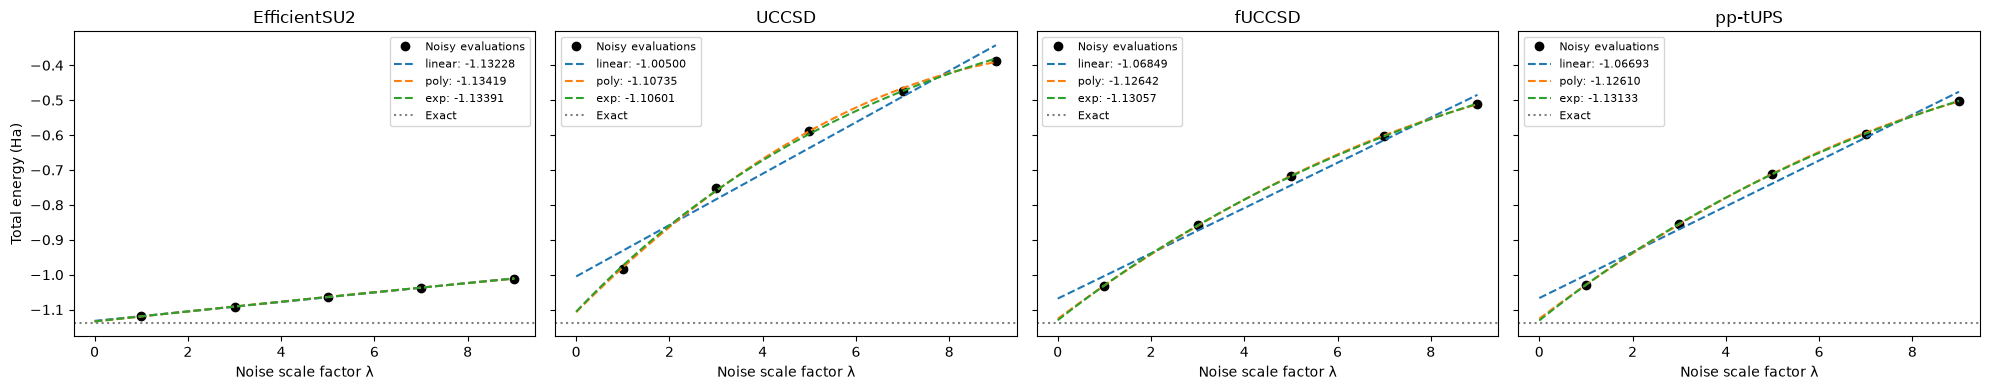

In [6]:
fig, axes = plt.subplots(1, len(ANSATZE), figsize=(5 * len(ANSATZE), 4), sharey=True)
x = np.linspace(0, max(ZNE().noise_factors), 100)

for ax, name in zip(axes, ANSATZE):
    r = results[name]
    zne = r["zne"]
    ax.plot(zne.lambdas, zne.energies, "ko", label="Noisy evaluations")
    for method in ["linear", "poly", "exp"]:
        E0, curve = zne.extrapolate(method)
        print(f"{name} | {method:6s}  E0 = {E0:.6f}  R² = {zne.r_squared(method):.6f}")
        ax.plot(x, [curve(xi) for xi in x], "--", label=f"{method}: {E0:.5f}")
    ax.axhline(r["E_exact"], color="gray", ls=":", label="Exact")
    ax.set_title(name)
    ax.set_xlabel("Noise scale factor λ")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Total energy (Ha)")
plt.tight_layout()
plt.show()

Choose the extrapolation for each ansatz from the plots:

In [13]:
zne_method = {
    "EfficientSU2": "poly",
    "UCCSD": "poly",
    "fUCCSD": "poly",
    "pp-tUPS": "poly"
}

for name in ANSATZE:
    r = results[name]
    r["E_zne"], _ = r["zne"].extrapolate(zne_method[name])
    print(f"{name:13s} ({zne_method[name]:6s})  Noisy error = {abs(r['E_noisy'] - r['E_exact']):.6f}   "
          f"ZNE error = {abs(r['E_zne'] - r['E_exact']):.6f} Ha")

EfficientSU2  (poly  )  Noisy error = 0.017674   ZNE error = 0.003119 Ha
UCCSD         (poly  )  Noisy error = 0.154009   ZNE error = 0.029952 Ha
fUCCSD        (poly  )  Noisy error = 0.105212   ZNE error = 0.010881 Ha
pp-tUPS       (poly  )  Noisy error = 0.106959   ZNE error = 0.011203 Ha


## CDR

In [8]:
for name in ANSATZE:
    r = results[name]
    cdr = CDR()
    print(f"{name}: ", end="")
    circuits = cdr.training_circuits(r["transpiled_ansatz"])
    cdr.training_data(circuits, r["hamiltonian"], e_nuc)
    cdr.save(f"data/H2_{name}_CDR_{date}.npz")
    r["cdr"] = cdr

EfficientSU2: n = 18 non-Clifford gates, k = 2 -> C(n, k) = 153
UCCSD: n = 8 non-Clifford gates, k = 2 -> C(n, k) = 28
fUCCSD: n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
pp-tUPS: n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45


To skip the slow part later, load saved training data instead:

```python
cdr = CDR()
cdr.load("data/H2_fUCCSD_CDR_<date>.npz")
results["fUCCSD"]["cdr"] = cdr
```

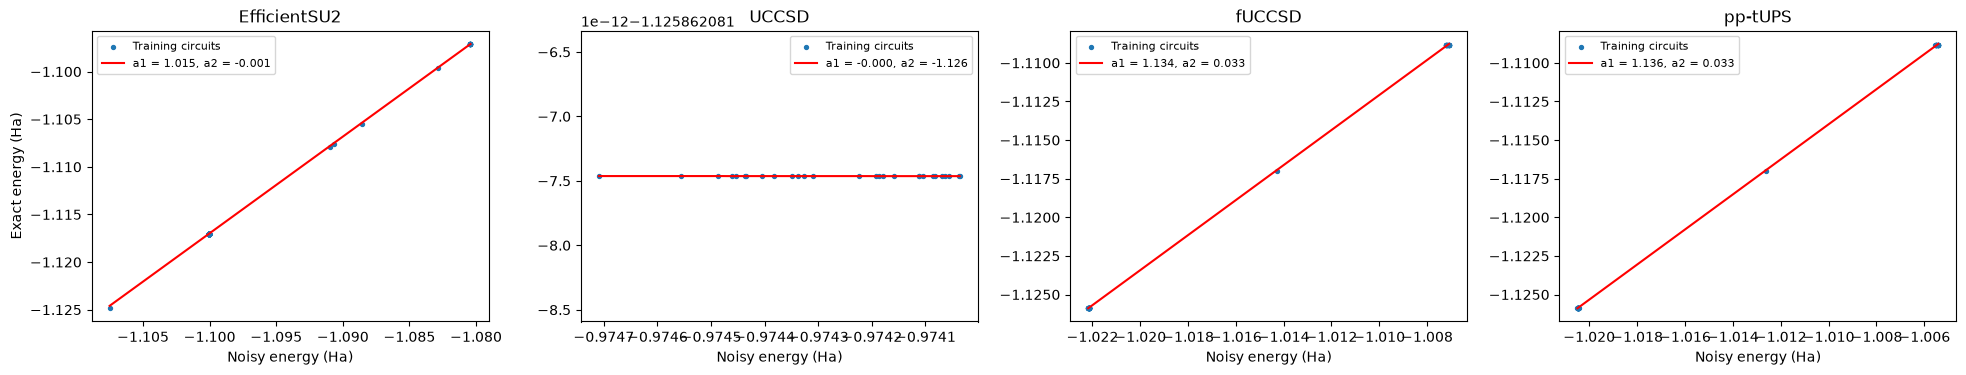

In [9]:
fig, axes = plt.subplots(1, len(ANSATZE), figsize=(5 * len(ANSATZE), 4))

for ax, name in zip(axes, ANSATZE):
    r = results[name]
    cdr = r["cdr"]
    a1, a2 = cdr.fit()
    r["E_cdr"] = float(cdr.mitigate(r["E_noisy"]))

    x = np.linspace(cdr.X_noisy.min(), cdr.X_noisy.max(), 100)
    ax.scatter(cdr.X_noisy, cdr.X_exact, s=8, label="Training circuits")
    ax.plot(x, cdr.mitigate(x), "r-", label=f"a1 = {a1:.3f}, a2 = {a2:.3f}")
    ax.set_title(name)
    ax.set_xlabel("Noisy energy (Ha)")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Exact energy (Ha)")
plt.tight_layout()
plt.show()

## M0

In [10]:
M0_ANSATZE = ["fUCCSD", "pp-tUPS"]   # M0 only works with SlowQuant ansatze

for name in ANSATZE:
    r = results[name]
    if name in M0_ANSATZE:
        r["E_noisy_m0"], r["E_m0"] = M0().run(name, r["theta_opt"])
        print(f"{name:13s} Noisy (sampler) error = {abs(r['E_noisy_m0'] - r['E_exact']):.6f}   "
              f"M0 error = {abs(r['E_m0'] - r['E_exact']):.6f} Ha")
    else:
        r["E_noisy_m0"] = r["E_m0"] = np.nan

fUCCSD        Noisy (sampler) error = 0.132825   M0 error = 0.004043 Ha
pp-tUPS       Noisy (sampler) error = 0.145515   M0 error = 0.001899 Ha


## Summary

In [14]:
print(f"{'Ansatz':13s} {'Exact':>11s} {'Noisy':>11s} {'ZNE':>11s} {'CDR':>11s} {'M0':>11s}   "
      f"{'err Noisy':>10s} {'err ZNE':>10s} {'err CDR':>10s} {'err M0':>10s}")
for name in ANSATZE:
    r = results[name]
    errs = [abs(r[k] - r["E_exact"]) for k in ("E_noisy", "E_zne", "E_cdr", "E_m0")]
    print(f"{name:13s} {r['E_exact']:11.6f} {r['E_noisy']:11.6f} {r['E_zne']:11.6f} "
          f"{r['E_cdr']:11.6f} {r['E_m0']:11.6f}   " + " ".join(f"{e:10.2e}" for e in errs))

Ansatz              Exact       Noisy         ZNE         CDR          M0    err Noisy    err ZNE    err CDR     err M0
EfficientSU2    -1.137306   -1.119632   -1.134187   -1.136896         nan     1.77e-02   3.12e-03   4.10e-04        nan
UCCSD           -1.137306   -0.983297   -1.107354   -1.125862         nan     1.54e-01   3.00e-02   1.14e-02        nan
fUCCSD          -1.137306   -1.032094   -1.126425   -1.137132   -1.133263     1.05e-01   1.09e-02   1.74e-04   4.04e-03
pp-tUPS         -1.137306   -1.030347   -1.126103   -1.137082   -1.139206     1.07e-01   1.12e-02   2.24e-04   1.90e-03


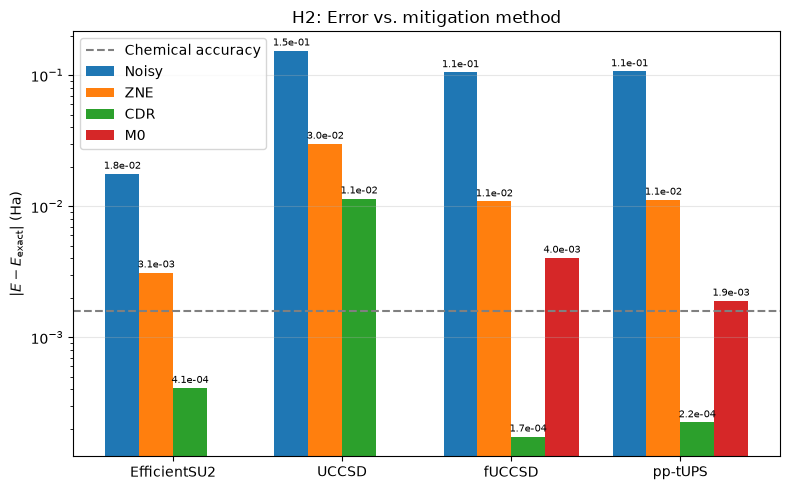

In [15]:
import numpy as np
import matplotlib.pyplot as plt

methods = [("E_noisy", "Noisy"), ("E_zne", "ZNE"), ("E_cdr", "CDR"), ("E_m0", "M0")]
w = 0.2
x = np.arange(len(ANSATZE))

fig, ax = plt.subplots(figsize=(8, 5))
for i, (key, label) in enumerate(methods):
    errs = [abs(results[n][key] - results[n]["E_exact"]) for n in ANSATZE]
    bars = ax.bar(x + (i - 1.5) * w, errs, w, label=label)
    ax.bar_label(bars, labels=["" if np.isnan(e) else f"{e:.1e}" for e in errs], fontsize=7, padding=2)

plt.axhline(1.6e-3, color="gray", ls="--", label="Chemical accuracy")

ax.set_xticks(x)
ax.set_xticklabels(ANSATZE)
ax.set_ylabel(r"$|E - E_\mathrm{exact}|$ (Ha)")
ax.set_yscale("log")
ax.set_title("H2: Error vs. mitigation method")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"plots/H2_mitigation_errors_{date}.png", dpi=200)
plt.show()